<a href="https://www.kaggle.com/code/vegash07/nasa-space-apps-challenge-final?scriptVersionId=370347995" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Mars Analog Finder

Given a Mars coordinate, search the whole land surface of Earth for terrain that resembles it, then explain where the analogy holds and where it breaks. Built for the NASA Space Apps Challenge 2026: *Identify Earth Locations that Analog the Permanent Moon Base Locations and Mars*.

**Before running:** Settings → Internet **On**; Add-ons → Secrets → add `EARTHDATA_USERNAME`, `EARTHDATA_PASSWORD`.
Raw downloads go to `/kaggle/temp` (wiped when the session ends). Small results are saved to `/kaggle/working/persist`.

Run order: **A** setup → **B** write modules → **C** download → **D** build → **E** save → **F** search.
In a later session skip C to E: Run **G** instead, as the dataset is already added.

**How a search is scored.** Terrain shape similarity (embedding distance, calibrated against the whole index) is blended with physical gates.
Every search prints a *gate report* that lists which gates ran, which were skipped and why, and which used an assumed Mars value.
A gate only runs when both sides have data, so a Mars raster that is missing means that gate is skipped, not guessed.

| group | gates |
|---|---|
| thermal | thermal_inertia, diurnal_range, mean_temp |
| surface | albedo, slope, roughness, relief |
| atmosphere, water, life | pressure, aridity, vegetation, ice_proxy |
| composition, insolation | mafic, latitude |


## A. Setup

In [1]:
import os
from kaggle_secrets import UserSecretsClient
sec = UserSecretsClient()
for k in ("EARTHDATA_USERNAME", "EARTHDATA_PASSWORD"):
    os.environ[k] = sec.get_secret(k)

os.environ["DATA_DIR"] = "/kaggle/temp/data"
PERSIST = "/kaggle/working/persist"
# Mars MOLA + HRSC blended DEM, 200 m/px
os.environ["MARS_MOLA_DEM_URL"] = "https://planetarymaps.usgs.gov/mosaic/Mars/HRSC_MOLA_Blend/Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif"

In [2]:
!pip install -q earthaccess python-dotenv faiss-cpu rasterio h5py tqdm

!apt-get install -y -qq libhdf4-dev > /dev/null 2>&1
!pip install -q pyhdf

In [3]:
import importlib
try:
    importlib.import_module("pyhdf.SD"); print("pyhdf ok")
except Exception as e:
    print("pyhdf failed:", e, "\nMODIS .hdf layers will not build, so the thermal, albedo, vegetation and land gates will be skipped")

pyhdf ok


## B. Modules

In [4]:
%%writefile config.py

from __future__ import annotations

import os
from dataclasses import dataclass
from pathlib import Path

import math

from dotenv import load_dotenv

load_dotenv()

# paths
DATA_DIR = Path(os.getenv("DATA_DIR", "./data")).resolve()
DEM_DIR = DATA_DIR / "earth" / "dem"            # NASADEM tiles (.tif / .hgt)
RAW_DIR = DATA_DIR / "earth" / "raw"            # raw MODIS / GPM / ASTER downloads
LAYER_DIR = DATA_DIR / "earth" / "layers"       # global gate grids (.npz)
S2_DIR = DATA_DIR / "earth" / "sentinel2"       # candidate Sentinel-2 products
MARS_DIR = DATA_DIR / "mars"                    # Mars GeoTIFFs
INDEX_DIR = DATA_DIR / "index"                  # embeddings + metadata
OUT_DIR = DATA_DIR / "results"                  # ranked csv + figures
MANUAL_DIR = DATA_DIR / "manual"

for _d in (DEM_DIR, RAW_DIR, LAYER_DIR, S2_DIR, MARS_DIR, INDEX_DIR, OUT_DIR, MANUAL_DIR):
    _d.mkdir(parents=True, exist_ok=True)

PATCH_PX = 64
MPP = 500.0                                    # metres per pixel
PATCH_KM = PATCH_PX * MPP / 1000.0             # 32 km
STRIDE_KM = 16.0                               # 50 percent overlap on Earth

EARTH_RADIUS_M = 6_371_008.8
MARS_RADIUS_M = 3_396_190.0                    # Mars 2000 sphere, the radius used by USGS MOLA mosaics

M_PER_DEG_EARTH = 2 * math.pi * EARTH_RADIUS_M / 360.0
M_PER_DEG_MARS = 2 * math.pi * MARS_RADIUS_M / 360.0

MARS_P0_MBAR = 6.1
MARS_SCALE_HEIGHT_M = 11_100.0

MARS_URLS = {
    "mola_dem": os.getenv(
        "MARS_MOLA_DEM_URL",
        "https://planetarymaps.usgs.gov/mosaic/Mars/HRSC_MOLA_Blend/Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif"),
    "thermal_inertia": os.getenv("MARS_THERMAL_INERTIA_URL", ""),
    "albedo": os.getenv(
        "MARS_ALBEDO_URL",
        "https://planetarymaps.usgs.gov/mosaic/Mars_MGS_TES_Albedo_mosaic_global_7410m.tif"),
    "day_temp": os.getenv("MARS_DAY_TEMP_URL", ""),
    "night_temp": os.getenv("MARS_NIGHT_TEMP_URL", ""),
    "hydrogen": os.getenv("MARS_HYDROGEN_URL", ""),
    "mineral": os.getenv("MARS_MINERAL_URL", ""),
}


def mars_path(name: str) -> Path:
    return MARS_DIR / f"{name}.tif"

EARTHDATA = {
    "nasadem": dict(short_name="NASADEM_HGT", version="001", dest=DEM_DIR),
    "lst": dict(short_name="MOD11C3", version="061", dest=RAW_DIR / "lst"),
    "albedo": dict(short_name="MCD43C3", version="061", dest=RAW_DIR / "albedo"),
    "ndvi": dict(short_name="MOD13C2", version="061", dest=RAW_DIR / "ndvi"),
    "precip": dict(short_name="GPM_3IMERGM", version="07", dest=RAW_DIR / "precip"),
    "aster": dict(short_name="AG1km", version="003", dest=RAW_DIR / "aster"),
}

# gate settings
@dataclass
class GateSpec:
    name: str
    earth_layer: str            # layer key in LAYER_DIR, or a column name when source == "column"
    mars_layer: str | None      # key in MARS_URLS, None means "no Mars raster for this gate"
    mars_assumed: float | None = None   # fallback Mars value when there is no raster
    mode: str = "quantile"      # quantile | absolute | log
    scale: float = 1.0          # absolute / log mode: difference that counts as fully different
    source: str = "layer"       # layer: global Earth grid | column: computed from the DEM patch
    note: str = ""


GATES = [
    # thermal
    GateSpec("thermal_inertia", "apparent_ti", "thermal_inertia", mode="quantile"),
    GateSpec("diurnal_range", "lst_range", None, mars_assumed=80.0, mode="absolute", scale=60.0,
             note="Mars value 80 K is a PLACEHOLDER, replace it with a cited number or add day_temp and night_temp rasters"),
    GateSpec("mean_temp", "mean_lst", None, mars_assumed=None, mode="absolute", scale=30.0,
             note="needs day_temp and night_temp rasters, or set mars_assumed to a cited annual mean in kelvin"),
    # surface
    GateSpec("albedo", "albedo", "albedo", mode="absolute", scale=0.25),
    GateSpec("slope", "slope_p90", None, mode="absolute", scale=10.0, source="column",
             note="90th percentile slope in degrees at 500 m/px"),
    GateSpec("roughness", "rough_1km", None, mode="absolute", scale=0.7, source="column",
             note="log10(1 + RMS height difference at 1 km lag)"),
    GateSpec("relief", "relief_log", None, mode="absolute", scale=0.8, source="column",
             note="log10(1 + 5 to 95 percentile elevation range)"),
    # atmosphere, water, life
    GateSpec("pressure", "pressure_mbar", None, mode="log", scale=3.0, source="column",
             note="surface pressure from elevation, log scale. Earth is always far above Mars, higher sites score a bit better"),
    GateSpec("aridity", "precip_mm_month", None, mars_assumed=0.0, mode="absolute", scale=60.0),
    GateSpec("vegetation", "ndvi", None, mars_assumed=0.0, mode="absolute", scale=0.3),
    GateSpec("ice_proxy", "cold_fraction", "hydrogen", mode="quantile"),
    # composition, insolation
    GateSpec("mafic", "mafic_index", "mineral", mode="quantile"),
    GateSpec("latitude", "abs_lat", None, mode="absolute", scale=30.0, source="column",
             note="absolute latitude, crude proxy for insolation and seasonality"),
]

GATE_BY_NAME = {g.name: g for g in GATES}

HARD_LIMITS = {
    "ndvi_max": 0.25,
    "precip_mm_month_max": 120.0,
    "land_frac_min": 0.9,          # drops patches that are mostly sea or lake
}

PROFILES = {
    "balanced": dict(terrain=0.5, gate_weights=dict(
        thermal_inertia=1, diurnal_range=1, mean_temp=1, albedo=1, slope=0.5, roughness=0.5, relief=0.5,
        pressure=0.5, aridity=1, vegetation=1, ice_proxy=1, mafic=1, latitude=0.5)),
    "mobility": dict(terrain=0.7, gate_weights=dict(
        thermal_inertia=2, diurnal_range=0.5, mean_temp=0.5, albedo=0.5, slope=2, roughness=1.5, relief=0.5,
        pressure=0, aridity=1, vegetation=1, ice_proxy=0, mafic=0, latitude=0)),
    "ice": dict(terrain=0.3, gate_weights=dict(
        thermal_inertia=1, diurnal_range=1, mean_temp=1.5, albedo=0.5, slope=0.5, roughness=0.5, relief=0.5,
        pressure=0.5, aridity=0.5, vegetation=1, ice_proxy=3, mafic=0, latitude=1)),
    "minerals": dict(terrain=0.3, gate_weights=dict(
        thermal_inertia=0.5, diurnal_range=0.5, mean_temp=0, albedo=1, slope=0, roughness=0, relief=0,
        pressure=0, aridity=1, vegetation=1, ice_proxy=0, mafic=3, latitude=0)),
}

TOP_K = 500

Writing config.py


In [5]:
%%writefile readers.py

from __future__ import annotations

import math
from dataclasses import dataclass
from pathlib import Path

import h5py
import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import from_bounds

import config as C


# geometry
def patch_bounds(lat: float, lon: float, planet: str = "earth") -> tuple[float, float, float, float]:
    """(west, south, east, north) in degrees for a PATCH_KM square centred on lat, lon."""
    m_per_deg = C.M_PER_DEG_EARTH if planet == "earth" else C.M_PER_DEG_MARS
    half_m = C.PATCH_KM * 1000.0 / 2.0
    dlat = half_m / m_per_deg
    coslat = max(math.cos(math.radians(lat)), 0.05)
    dlon = half_m / (m_per_deg * coslat)
    return lon - dlon, lat - dlat, lon + dlon, lat + dlat


def _lon_for_raster(src: rasterio.DatasetReader, lon: float) -> float:
    """Many Mars mosaics use 0..360 longitude, Earth tiles use -180..180."""
    if src.bounds.right > 180.5:
        return lon % 360.0
    return (lon + 180.0) % 360.0 - 180.0


def _read_box(src, w: float, s: float, e: float, n: float, out_h: int, out_w: int, band: int) -> np.ndarray:
    win = from_bounds(w, s, e, n, transform=src.transform)
    shrink = win.width > out_w or win.height > out_h
    resampling = Resampling.average if shrink else Resampling.bilinear
    arr = src.read(band, window=win, out_shape=(out_h, out_w), resampling=resampling,
                   boundless=True, masked=True)
    return np.ma.filled(arr.astype("float32"), np.nan)


def read_patch(src_or_path, lat: float, lon: float, planet: str = "earth", band: int = 1) -> np.ndarray:
    """Read a PATCH_PX square patch (float32, NaN for nodata) centred on lat, lon.

    Accepts a path or an already open rasterio dataset (faster in loops).
    """
    if isinstance(src_or_path, (str, Path)):
        with rasterio.open(src_or_path) as src:
            return read_patch(src, lat, lon, planet, band)
    src = src_or_path
    n_px = C.PATCH_PX
    lon_r = _lon_for_raster(src, lon)
    w, s, e, n = patch_bounds(lat, lon_r, planet)
    left, right = src.bounds.left, src.bounds.right
    span = right - left
    is_global = span >= 359.0
    if is_global and (w < left or e > right):
        if w < left:
            west_piece, east_piece = (w + span, right), (left, e)
        else:
            west_piece, east_piece = (w, right), (left, e - span)
        total = e - w
        n1 = int(np.clip(round(n_px * (west_piece[1] - west_piece[0]) / total), 1, n_px - 1))
        a = _read_box(src, west_piece[0], s, west_piece[1], n, n_px, n1, band)
        b = _read_box(src, east_piece[0], s, east_piece[1], n, n_px, n_px - n1, band)
        return np.hstack([a, b])
    return _read_box(src, w, s, e, n, n_px, n_px, band)


def patch_mean(path: str | Path, lat: float, lon: float, planet: str = "mars") -> float:
    p = read_patch(path, lat, lon, planet)
    if np.isnan(p).all():
        return float("nan")
    return float(np.nanmean(p))


# global grid
@dataclass
class GlobalGrid:
    """Regular lat/lon grid, row 0 is the northern edge, col 0 the western edge."""
    arr: np.ndarray
    lat_top: float = 90.0
    lon_left: float = -180.0
    dlat: float = 0.05
    dlon: float = 0.05

    def window_mean(self, west: float, south: float, east: float, north: float) -> float:
        r0 = int(math.floor((self.lat_top - north) / self.dlat))
        r1 = int(math.ceil((self.lat_top - south) / self.dlat))
        c0 = int(math.floor((west - self.lon_left) / self.dlon))
        c1 = int(math.ceil((east - self.lon_left) / self.dlon))
        r0, r1 = max(r0, 0), min(max(r1, r0 + 1), self.arr.shape[0])
        ncols = self.arr.shape[1]
        if c0 < 0 or c1 > ncols:                       # crosses the date line, wrap the columns
            cols = np.arange(c0, max(c1, c0 + 1)) % ncols
            win = self.arr[r0:r1][:, cols]
        else:
            c1 = max(c1, c0 + 1)
            win = self.arr[r0:r1, c0:c1]
        if win.size == 0 or np.isnan(win).all():
            return float("nan")
        return float(np.nanmean(win))

    def at(self, lat: float, lon: float, planet: str = "earth") -> float:
        w, s, e, n = patch_bounds(lat, lon, planet)
        return self.window_mean(w, s, e, n)

    def save(self, path: str | Path) -> None:
        np.savez_compressed(path, arr=self.arr.astype("float32"), lat_top=self.lat_top,
                            lon_left=self.lon_left, dlat=self.dlat, dlon=self.dlon)

    @staticmethod
    def load(path: str | Path) -> "GlobalGrid":
        z = np.load(path)
        return GlobalGrid(z["arr"], float(z["lat_top"]), float(z["lon_left"]),
                          float(z["dlat"]), float(z["dlon"]))


# HDF4
def read_hdf4_sds(path: str | Path, name: str) -> np.ndarray:
    """Read one SDS from an HDF4 / HDF-EOS2 file (MODIS CMG products)."""
    from pyhdf.SD import SD, SDC
    sd = SD(str(path), SDC.READ)
    try:
        return sd.select(name).get()
    finally:
        sd.end()


def read_cmg_hdf4(path: str | Path, sds: str, scale: float, fill: float | None,
                  valid: tuple[float, float] | None = None, offset: float = 0.0) -> GlobalGrid:
    raw = read_hdf4_sds(path, sds).astype("float64")
    bad = np.zeros(raw.shape, bool)
    if fill is not None:
        bad |= raw == fill
    if valid is not None:
        bad |= (raw < valid[0]) | (raw > valid[1])
    arr = raw * scale + offset
    arr[bad] = np.nan
    dlat = 180.0 / arr.shape[0]
    dlon = 360.0 / arr.shape[1]
    return GlobalGrid(arr.astype("float32"), 90.0, -180.0, dlat, dlon)


class RunningMean:

    def __init__(self) -> None:
        self.s: np.ndarray | None = None
        self.c: np.ndarray | None = None

    def add(self, arr: np.ndarray) -> None:
        a = np.asarray(arr, dtype="float64")
        if self.s is None:
            self.s = np.zeros(a.shape)
            self.c = np.zeros(a.shape)
        ok = np.isfinite(a)
        self.s[ok] += a[ok]
        self.c[ok] += 1

    def mean(self) -> np.ndarray:
        with np.errstate(all="ignore"):
            return np.where(self.c > 0, self.s / np.where(self.c > 0, self.c, 1), np.nan).astype("float32")


def mean_grids(grids: list[GlobalGrid]) -> GlobalGrid:
    rm = RunningMean()
    for g in grids:
        rm.add(g.arr)
    g0 = grids[0]
    return GlobalGrid(rm.mean(), g0.lat_top, g0.lon_left, g0.dlat, g0.dlon)


# MODIS CMG layer definitions
def read_mod11c3_lst(path: str | Path) -> tuple[GlobalGrid, GlobalGrid]:
    day = read_cmg_hdf4(path, "LST_Day_CMG", 0.02, 0, valid=(7500, 65535))
    night = read_cmg_hdf4(path, "LST_Night_CMG", 0.02, 0, valid=(7500, 65535))
    return day, night


def read_mcd43c3_albedo(path: str | Path) -> GlobalGrid:
    return read_cmg_hdf4(path, "Albedo_WSA_shortwave", 0.001, 32767, valid=(0, 1000))


def read_mod13c2_ndvi(path: str | Path) -> GlobalGrid:
    return read_cmg_hdf4(path, "CMG 0.05 Deg Monthly NDVI", 0.0001, -3000, valid=(-2000, 10000))


# GPM IMERG
def read_imerg_monthly(path: str | Path) -> GlobalGrid:
    """GPM IMERG monthly (HDF5). Returns precipitation in mm per month."""
    with h5py.File(path, "r") as f:
        ds = None

        def finder(name, obj):
            nonlocal ds
            if ds is None and isinstance(obj, h5py.Dataset) and name.split("/")[-1] == "precipitation":
                ds = obj
        f.visititems(finder)
        if ds is None:
            raise KeyError(f"no 'precipitation' dataset in {path}")
        arr = np.array(ds[...], dtype="float64")
        fill = ds.attrs.get("_FillValue", None)
        if fill is not None:
            arr[arr == float(np.ravel(fill)[0])] = np.nan
    arr = np.squeeze(arr)                       # (lon, lat) or (lat, lon)
    if arr.shape[0] > arr.shape[1]:             # IMERG v07 stores (lon, lat)
        arr = arr.T
    arr = np.flipud(arr)                        # file runs south to north, we want north first
    arr[arr < 0] = np.nan
    # monthly product is mm/hr, convert to mm per 30 days
    arr = arr * 24.0 * 30.0
    dlat = 180.0 / arr.shape[0]
    dlon = 360.0 / arr.shape[1]
    return GlobalGrid(arr.astype("float32"), 90.0, -180.0, dlat, dlon)


# ASTER
def read_aster_emissivity(path: str | Path) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    found: dict[str, np.ndarray] = {}
    with h5py.File(path, "r") as f:
        def finder(name, obj):
            if isinstance(obj, h5py.Dataset):
                for key, suffix in (("emis", "Emissivity/Mean"), ("lat", "Geolocation/Latitude"),
                                    ("lon", "Geolocation/Longitude")):
                    if name.endswith(suffix):
                        found[key] = obj[...]
        f.visititems(finder)
    missing = {"emis", "lat", "lon"} - found.keys()
    if missing:
        raise KeyError(f"{path}: missing datasets {missing}")
    emis = found["emis"].astype("float64") * 0.001
    emis[(emis <= 0) | (emis > 1.2)] = np.nan
    return emis, found["lat"].astype("float64"), found["lon"].astype("float64")


def aster_indices(emis: np.ndarray) -> dict[str, np.ndarray]:
    """Ninomiya style TIR indices. emis has bands 10..14 on axis 0."""
    b10, b11, b12, b13, b14 = emis
    with np.errstate(all="ignore"):
        return {
            "quartz_index": (b11 * b11) / (b10 * b12),
            "carbonate_index": b13 / b14,
            "mafic_index": b12 / b13,
        }


def bin_to_grid(values: np.ndarray, lat: np.ndarray, lon: np.ndarray, res: float,
                acc_sum: np.ndarray, acc_cnt: np.ndarray) -> None:
    values = np.asarray(values, dtype="float64").ravel()
    lat = np.asarray(lat, dtype="float64").ravel()
    lon = np.asarray(lon, dtype="float64").ravel()
    ok = np.isfinite(values) & np.isfinite(lat) & np.isfinite(lon)
    rows = np.floor((90.0 - lat[ok]) / res).astype(np.int64)
    cols = np.floor((lon[ok] + 180.0) / res).astype(np.int64)
    inside = (rows >= 0) & (rows < acc_sum.shape[0]) & (cols >= 0) & (cols < acc_sum.shape[1])
    flat = rows[inside] * acc_sum.shape[1] + cols[inside]
    acc_sum += np.bincount(flat, weights=values[ok][inside], minlength=acc_sum.size).reshape(acc_sum.shape)
    acc_cnt += np.bincount(flat, minlength=acc_cnt.size).reshape(acc_cnt.shape)

Writing readers.py


In [6]:
%%writefile terrain.py

from __future__ import annotations

import numpy as np
from scipy import ndimage

import config as C

SLOPE_EDGES = np.array([0, 1, 2, 3, 5, 7, 10, 15, 20, 30, 45, 90], dtype=float)
LAGS = (1, 2, 4, 8, 16)
N_STATS = 38


def fill_nan(dem: np.ndarray) -> np.ndarray:
    """Replace NaN with the nearest valid value, or zeros if there is nothing valid."""
    dem = np.asarray(dem, dtype="float64")
    bad = ~np.isfinite(dem)
    if not bad.any():
        return dem
    if bad.all():
        return np.zeros_like(dem)
    idx = ndimage.distance_transform_edt(bad, return_distances=False, return_indices=True)
    return dem[tuple(idx)]


def derivatives(dem: np.ndarray, mpp: float = C.MPP) -> dict[str, np.ndarray]:
    """Slope (deg), curvature (1/m, positive = convex), hillshade (0..1)."""
    z = fill_nan(dem)
    gy, gx = np.gradient(z, mpp)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    gyy, _ = np.gradient(gy, mpp)
    _, gxx = np.gradient(gx, mpp)
    curv = -(gxx + gyy)
    az, alt = np.radians(315.0), np.radians(45.0)
    aspect = np.arctan2(-gx, gy)
    slope_r = np.arctan(np.hypot(gx, gy))
    hs = np.sin(alt) * np.cos(slope_r) + np.cos(alt) * np.sin(slope_r) * np.cos(az - aspect)
    return {"slope": slope, "curvature": curv, "hillshade": np.clip(hs, 0, 1)}


def _structure_function(z: np.ndarray, lag: int) -> float:
    dx = z[:, lag:] - z[:, :-lag]
    dy = z[lag:, :] - z[:-lag, :]
    return float(np.sqrt(0.5 * (np.mean(dx ** 2) + np.mean(dy ** 2))))


def _radial_spectrum(z: np.ndarray, nbins: int = 10) -> np.ndarray:
    n = z.shape[0]
    win = np.outer(np.hanning(n), np.hanning(n))
    f = np.fft.fftshift(np.fft.fft2((z - z.mean()) * win))
    p = np.abs(f) ** 2
    yy, xx = np.indices(p.shape)
    r = np.hypot(yy - n / 2, xx - n / 2)
    edges = np.geomspace(1.0, n / 2, nbins + 1)
    out = np.zeros(nbins)
    for i in range(nbins):
        m = (r >= edges[i]) & (r < edges[i + 1])
        out[i] = p[m].mean() if m.any() else 0.0
    out = np.log10(out + 1e-12)
    return out - out.mean()


def stats_features(dem: np.ndarray, mpp: float = C.MPP) -> np.ndarray:
    z = fill_nan(dem)
    d = derivatives(z, mpp)
    slope, curv = d["slope"], d["curvature"]

    # 1. slope distribution
    hist, _ = np.histogram(slope, bins=SLOPE_EDGES)
    f_slope = hist / max(hist.sum(), 1)

    # 2. curvature distribution in 1/km 
    ck = curv * 1000.0
    q = np.percentile(ck, [5, 25, 50, 75, 95])
    sd = ck.std() + 1e-9
    skew = float(np.mean(((ck - ck.mean()) / sd) ** 3))
    f_curv = np.array([*np.arcsinh(q), skew, float((ck < 0).mean())])

    # 3. roughness across scales, log metres and Hurst-like slope
    sf = np.array([_structure_function(z, lag) for lag in LAGS])
    f_rough = np.log10(1.0 + sf)
    lags_m = np.array(LAGS) * mpp
    hurst = np.polyfit(np.log(lags_m), np.log(sf + 1e-6), 1)[0]

    # 4. spectral shape
    f_spec = _radial_spectrum(z, 10)

    # 5. relief
    f_relief = np.array([np.log10(1.0 + np.ptp(np.percentile(z, [5, 95]))), np.log10(1.0 + z.std())])

    # 6. anisotropy from the gradient structure tensor, rotation invariant
    gy, gx = np.gradient(z, mpp)
    jxx, jyy, jxy = (gx * gx).mean(), (gy * gy).mean(), (gx * gy).mean()
    tr = jxx + jyy + 1e-18
    disc = np.sqrt(((jxx - jyy) / 2) ** 2 + jxy ** 2)
    aniso = float(disc * 2 / tr)

    # 7. fraction of area in closed depressions
    smooth = ndimage.gaussian_filter(z, 1.0)
    pit_frac = float((smooth - ndimage.uniform_filter(smooth, 9) < -0.5 * z.std()).mean())

    return np.concatenate([f_slope, f_curv, f_rough, [hurst], f_spec, f_relief, [aniso], [pit_frac]]).astype("float32")


def patch_metrics(dem: np.ndarray, mpp: float = C.MPP) -> dict[str, float]:
    z = fill_nan(dem)
    slope = derivatives(z, mpp)["slope"]
    sf_1km = _structure_function(z, max(int(round(1000.0 / mpp)), 1))
    relief = float(np.ptp(np.percentile(z, [5, 95])))
    return {
        "slope_p50": float(np.percentile(slope, 50)),
        "slope_p90": float(np.percentile(slope, 90)),
        "rough_1km": float(np.log10(1.0 + sf_1km)),
        "relief_log": float(np.log10(1.0 + relief)),
        "mean_elev": float(z.mean()),
    }


def feature_image(dem: np.ndarray, mpp: float = C.MPP) -> np.ndarray:
    d = derivatives(dem, mpp)
    hs = d["hillshade"]
    sl = np.clip(d["slope"] / 30.0, 0, 1)
    cv = d["curvature"]
    s = np.percentile(np.abs(cv), 98) + 1e-12
    cv = np.clip(cv / (2 * s) + 0.5, 0, 1)
    return np.stack([hs, sl, cv]).astype("float32")


def dihedral_variants(dem: np.ndarray) -> list[np.ndarray]:
    out = []
    for k in range(4):
        r = np.rot90(dem, k)
        out.append(r)
        out.append(np.fliplr(r))
    return out

Writing terrain.py


In [7]:
%%writefile embed.py

from __future__ import annotations

import argparse
import math
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
from tqdm import tqdm

import config as C
import readers as R
import terrain as T


# embedder
class Embedder:
    def __init__(self, backend: str = "stats", device: str | None = None):
        if backend not in ("stats", "dinov2", "both"):
            raise ValueError(backend)
        self.backend = backend
        self.device = device
        self._model = None

    def _load_dino(self):
        import torch
        self._torch = torch
        if self.device is None:
            self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self._model = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14").to(self.device).eval()
        self._mean = torch.tensor([0.485, 0.456, 0.406], device=self.device).view(1, 3, 1, 1)
        self._std = torch.tensor([0.229, 0.224, 0.225], device=self.device).view(1, 3, 1, 1)

    def _dino(self, patches: np.ndarray, batch: int = 64) -> np.ndarray:
        if self._model is None:
            self._load_dino()
        torch = self._torch
        out = []
        for i in range(0, len(patches), batch):
            imgs = np.stack([T.feature_image(p) for p in patches[i:i + batch]])
            x = torch.from_numpy(imgs).to(self.device)
            x = torch.nn.functional.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
            x = (x - self._mean) / self._std
            with torch.no_grad():
                out.append(self._model(x).cpu().numpy())
        return np.concatenate(out).astype("float32")

    def _stats(self, patches: np.ndarray) -> np.ndarray:
        return np.stack([T.stats_features(p) for p in patches])

    def embed(self, patches: np.ndarray) -> np.ndarray:
        """patches: [N, PATCH_PX, PATCH_PX] elevation in metres -> [N, D] raw features."""
        patches = np.asarray(patches)
        if self.backend == "stats":
            return self._stats(patches)
        if self.backend == "dinov2":
            return self._dino(patches)
        return np.concatenate([self._stats(patches), self._dino(patches)], axis=1)


# tile patches
def dem_files() -> list[Path]:
    files = []
    for ext in ("*.hgt", "*.tif", "*.tiff"):
        files += list(C.DEM_DIR.glob(ext))
        files += list(C.MANUAL_DIR.glob(ext))
    return sorted(files)


def tile_centres(bounds: tuple[float, float, float, float]) -> list[tuple[float, float]]:
    w, s, e, n = bounds
    half_m = C.PATCH_KM * 1000.0 / 2.0
    step_m = C.STRIDE_KM * 1000.0
    dlat_half = half_m / C.M_PER_DEG_EARTH
    dlat_step = step_m / C.M_PER_DEG_EARTH
    centres = []
    lat = s + dlat_half
    while lat <= n - dlat_half + 1e-9:
        coslat = max(math.cos(math.radians(lat)), 0.05)
        dlon_half = half_m / (C.M_PER_DEG_EARTH * coslat)
        dlon_step = step_m / (C.M_PER_DEG_EARTH * coslat)
        lon = w + dlon_half
        while lon <= e - dlon_half + 1e-9:
            centres.append((lat, lon))
            lon += dlon_step
        lat += dlat_step
    return centres


def usable(patch: np.ndarray, max_nan: float = 0.05, min_std: float = 0.5) -> bool:
    if np.isnan(patch).mean() > max_nan:
        return False
    return float(np.nanstd(patch)) >= min_std


def patches_from_tile(path: Path) -> tuple[np.ndarray, list[tuple[float, float]]]:
    keep_p, keep_c = [], []
    with rasterio.open(path) as src:
        b = src.bounds
        for lat, lon in tile_centres((b.left, b.bottom, b.right, b.top)):
            p = R.read_patch(src, lat, lon, "earth")
            if usable(p):
                keep_p.append(T.fill_nan(p).astype("float32"))
                keep_c.append((lat, lon))
    if not keep_p:
        return np.empty((0, C.PATCH_PX, C.PATCH_PX), "float32"), []
    return np.stack(keep_p), keep_c


# ------------------------------------------------------------- scaling
def block_weights(backend: str, dim: int) -> np.ndarray:
    if backend == "both" and dim > T.N_STATS:
        return np.concatenate([np.full(T.N_STATS, 1.0 / math.sqrt(T.N_STATS)),
                               np.full(dim - T.N_STATS, 1.0 / math.sqrt(dim - T.N_STATS))]).astype("float32")
    return np.ones(dim, "float32")


def fit_scaler(x: np.ndarray, backend: str = "stats") -> dict[str, np.ndarray]:
    mu = x.mean(axis=0)
    sd = x.std(axis=0)
    sd[sd < 1e-8] = 1.0
    return {"mu": mu.astype("float32"), "sd": sd.astype("float32"), "w": block_weights(backend, x.shape[1])}


def apply_scaler(x: np.ndarray, sc: dict[str, np.ndarray]) -> np.ndarray:
    w = sc.get("w", 1.0)
    return (((x - sc["mu"]) / sc["sd"]) * w).astype("float32")


# build
def build_index(backend: str = "stats", max_tiles: int | None = None) -> None:
    files = dem_files()
    if not files:
        raise SystemExit(f"No DEM tiles in {C.DEM_DIR}. Run: python download.py earth-dem --bbox W S E N")
    if max_tiles:
        files = files[:max_tiles]
    emb = Embedder(backend)
    feats, meta = [], []
    for path in tqdm(files, desc="tiles"):
        try:
            patches, centres = patches_from_tile(path)
        except Exception as e:
            print(f"skip {path.name}: {e}")
            continue
        if len(patches) == 0:
            continue
        feats.append(emb.embed(patches))
        for p, (lat, lon) in zip(patches, centres):
            meta.append(dict(lat=lat, lon=lon, tile=str(path), mean_elev=float(p.mean()),
                             relief=float(np.ptp(np.percentile(p, [5, 95])))))
    if not feats:
        raise SystemExit("no usable patches found")
    x = np.concatenate(feats)
    sc = fit_scaler(x, backend)
    np.save(C.INDEX_DIR / "embeddings.npy", apply_scaler(x, sc))
    np.savez(C.INDEX_DIR / "scaler.npz", **sc, backend=backend)
    pd.DataFrame(meta).to_csv(C.INDEX_DIR / "meta.csv", index=False)
    print(f"indexed {len(x)} patches from {len(files)} tiles, dim {x.shape[1]}, backend {backend}")


def main() -> None:
    ap = argparse.ArgumentParser()
    sub = ap.add_subparsers(dest="cmd", required=True)
    b = sub.add_parser("build")
    b.add_argument("--backend", default="stats", choices=["stats", "dinov2", "both"])
    b.add_argument("--max-tiles", type=int, default=None)
    a = ap.parse_args()
    if a.cmd == "build":
        build_index(a.backend, a.max_tiles)


if __name__ == "__main__":
    main()

Writing embed.py


In [8]:
%%writefile gates.py

from __future__ import annotations

import argparse
import os
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import transform as warp_transform
from rasterio.windows import Window

import config as C
import readers as R
import terrain as T


def _glob_ci(folder: Path, *patterns: str) -> list[Path]:
    out: list[Path] = []
    for p in patterns:
        out += list(folder.glob(p)) + list(folder.glob(p.upper())) + list(folder.glob(p.lower()))
    return sorted(set(out))


def _grid_like(arr: np.ndarray) -> R.GlobalGrid:
    return R.GlobalGrid(arr.astype("float32"), 90.0, -180.0, 180.0 / arr.shape[0], 360.0 / arr.shape[1])


# layer building
def build_layers() -> None:
    made: list[str] = []

    lst_files = _glob_ci(C.RAW_DIR / "lst", "*.hdf")
    rng_grid = None
    if lst_files:
        rm_range, rm_cold, rm_mean, rm_valid = (R.RunningMean() for _ in range(4))
        for f in lst_files:
            day, night = R.read_mod11c3_lst(f)
            mean_t = (day.arr + night.arr) / 2.0
            rm_range.add(day.arr - night.arr)
            rm_mean.add(mean_t)
            rm_cold.add(np.where(np.isnan(mean_t), np.nan, (mean_t < 273.15).astype("float32")))
            rm_valid.add(np.isfinite(mean_t).astype("float32"))
        rng_grid = _grid_like(rm_range.mean())
        rng_grid.save(C.LAYER_DIR / "lst_range.npz")
        _grid_like(rm_mean.mean()).save(C.LAYER_DIR / "mean_lst.npz")
        _grid_like(rm_cold.mean()).save(C.LAYER_DIR / "cold_fraction.npz")
        # 1 where any month had a land temperature, 0 over open water. A window mean gives the land share.
        _grid_like((rm_valid.mean() > 0).astype("float32")).save(C.LAYER_DIR / "land_frac.npz")
        made += ["lst_range", "mean_lst", "cold_fraction", "land_frac"]

    alb_files = _glob_ci(C.RAW_DIR / "albedo", "*.hdf")
    alb_grid = None
    if alb_files:
        rm = R.RunningMean()
        for f in alb_files:
            rm.add(R.read_mcd43c3_albedo(f).arr)
        alb_grid = _grid_like(rm.mean())
        alb_grid.save(C.LAYER_DIR / "albedo.npz")
        made.append("albedo")

    if alb_grid is not None and rng_grid is not None and alb_grid.arr.shape == rng_grid.arr.shape:
        with np.errstate(all="ignore"):
            r = np.where(rng_grid.arr > 1.0, rng_grid.arr, np.nan)
            ati = (1.0 - alb_grid.arr) / r * 100.0
        _grid_like(ati).save(C.LAYER_DIR / "apparent_ti.npz")
        made.append("apparent_ti")

    ndvi_files = _glob_ci(C.RAW_DIR / "ndvi", "*.hdf")
    if ndvi_files:
        rm = R.RunningMean()
        for f in ndvi_files:
            rm.add(R.read_mod13c2_ndvi(f).arr)
        _grid_like(rm.mean()).save(C.LAYER_DIR / "ndvi.npz")
        made.append("ndvi")

    pr_files = _glob_ci(C.RAW_DIR / "precip", "*.hdf5", "*.h5", "*.nc4")
    if pr_files:
        rm = R.RunningMean()
        first = None
        for f in pr_files:
            g = R.read_imerg_monthly(f)
            first = first or g
            rm.add(g.arr)
        R.GlobalGrid(rm.mean(), 90.0, -180.0, first.dlat, first.dlon).save(C.LAYER_DIR / "precip_mm_month.npz")
        made.append("precip_mm_month")

    as_files = _glob_ci(C.RAW_DIR / "aster", "*.h5", "*.hdf5")
    if as_files:
        res = 0.05
        shape = (int(180 / res), int(360 / res))
        names = ("quartz_index", "carbonate_index", "mafic_index")
        sums = {k: np.zeros(shape) for k in names}
        cnts = {k: np.zeros(shape) for k in names}       # one count grid per index
        for f in as_files:
            try:
                emis, lat, lon = R.read_aster_emissivity(f)
            except KeyError as e:
                print(f"skip {f.name}: {e}")
                continue
            for k, v in R.aster_indices(emis).items():
                R.bin_to_grid(v, lat, lon, res, sums[k], cnts[k])
        with np.errstate(all="ignore"):
            for k in names:
                arr = np.where(cnts[k] > 0, sums[k] / np.where(cnts[k] > 0, cnts[k], 1), np.nan)
                R.GlobalGrid(arr.astype("float32"), 90.0, -180.0, res, res).save(C.LAYER_DIR / f"{k}.npz")
        made += list(names)

    print("built layers:", made if made else "none, no raw files found (run download.py earth-layers)")


# distributions
class EarthLayers:
    def __init__(self) -> None:
        self._grids: dict[str, R.GlobalGrid] = {}
        self._dist: dict[str, np.ndarray] = {}

    def has(self, name: str) -> bool:
        return (C.LAYER_DIR / f"{name}.npz").exists()

    def grid(self, name: str) -> R.GlobalGrid:
        if name not in self._grids:
            self._grids[name] = R.GlobalGrid.load(C.LAYER_DIR / f"{name}.npz")
        return self._grids[name]

    def value(self, name: str, lat: float, lon: float) -> float:
        return self.grid(name).at(lat, lon, "earth")

    def dist(self, name: str) -> np.ndarray:
        if name not in self._dist:
            a = self.grid(name).arr
            v = a[np.isfinite(a)]
            if v.size > 400_000:
                v = np.random.default_rng(0).choice(v, 400_000, replace=False)
            self._dist[name] = np.sort(v)
        return self._dist[name]


class MarsTargets:

    def __init__(self, lat: float, lon: float, metrics: dict[str, float] | None = None) -> None:
        self.lat, self.lon = lat, lon
        self.metrics = metrics or {}
        self._dist: dict[str, np.ndarray | None] = {}

    @staticmethod
    def _exists(name: str) -> bool:
        return C.mars_path(name).exists()

    def _have_temps(self) -> bool:
        return self._exists("day_temp") and self._exists("night_temp")

    def value(self, spec: C.GateSpec) -> tuple[float, str]:
        if spec.source == "column":
            return float(self.metrics.get(spec.earth_layer, np.nan)), "mars DEM"
        if spec.name in ("diurnal_range", "mean_temp") and self._have_temps():
            d = R.patch_mean(C.mars_path("day_temp"), self.lat, self.lon)
            n = R.patch_mean(C.mars_path("night_temp"), self.lat, self.lon)
            return (d - n if spec.name == "diurnal_range" else (d + n) / 2.0), "raster"
        if spec.mars_layer and self._exists(spec.mars_layer):
            return R.patch_mean(C.mars_path(spec.mars_layer), self.lat, self.lon), "raster"
        if spec.mars_assumed is not None:
            return float(spec.mars_assumed), "assumed"
        return float("nan"), "none"

    @staticmethod
    def _decimated(name: str, shape: tuple[int, int] | None = None) -> np.ndarray:
        with rasterio.open(C.mars_path(name)) as src:
            h, w = shape or (max(src.height // 20, 8), max(src.width // 20, 8))
            return np.ma.filled(src.read(1, out_shape=(h, w), masked=True).astype("float32"), np.nan)

    def dist(self, spec: C.GateSpec) -> np.ndarray | None:
        if spec.name in self._dist:
            return self._dist[spec.name]
        arr = None
        if spec.name == "diurnal_range" and self._have_temps():
            d = self._decimated("day_temp")
            n = self._decimated("night_temp", d.shape)
            arr = d - n
        elif spec.mars_layer and self._exists(spec.mars_layer):
            arr = self._decimated(spec.mars_layer)
        if arr is None:
            self._dist[spec.name] = None
        else:
            v = np.sort(arr[np.isfinite(arr)])
            self._dist[spec.name] = v if v.size else None
        return self._dist[spec.name]


def _pct(sorted_vals: np.ndarray, x: float) -> float:
    return float(np.searchsorted(sorted_vals, x) / max(len(sorted_vals), 1))


# DEM based gates
def earth_pressure_mbar(h_m) -> np.ndarray:
    """Standard atmosphere pressure at elevation h (metres)."""
    h = np.asarray(h_m, dtype="float64")
    return 1013.25 * np.clip(1.0 - 2.25577e-5 * h, 1e-3, None) ** 5.25588


def mars_pressure_mbar(h_m) -> np.ndarray:
    """Exponential atmosphere with the mean Mars scale height."""
    return C.MARS_P0_MBAR * np.exp(-np.asarray(h_m, dtype="float64") / C.MARS_SCALE_HEIGHT_M)


def add_patch_metrics(df: pd.DataFrame) -> pd.DataFrame:
    """Slope, roughness and relief of each shortlisted Earth patch, read back from its DEM tile."""
    opened: dict[str, rasterio.DatasetReader | None] = {}
    rows = []
    try:
        for tile, lat, lon in zip(df["tile"], df["lat"], df["lon"]):
            if tile not in opened:
                opened[tile] = rasterio.open(tile) if os.path.exists(tile) else None
            src = opened[tile]
            if src is None:
                rows.append({})
                continue
            p = R.read_patch(src, lat, lon, "earth")
            rows.append(T.patch_metrics(p) if np.isfinite(p).mean() > 0.9 else {})
    finally:
        for s in opened.values():
            if s is not None:
                s.close()
    m = pd.DataFrame(rows, index=df.index)
    for c in m.columns:
        if c == "mean_elev" and "mean_elev" in df:
            continue
        df[c] = m[c]
    return df


# scoring
def _verdict(s: float) -> str:
    return "n/a" if not np.isfinite(s) else "match" if s >= 0.75 else "partial" if s >= 0.4 else "MISMATCH"


def score_gates(cands: pd.DataFrame, mars_lat: float, mars_lon: float, profile: str = "balanced",
                mars_patch: np.ndarray | None = None, layers: EarthLayers | None = None) -> pd.DataFrame:
    layers = layers or EarthLayers()
    prof = C.PROFILES[profile]
    df = cands.copy()
    report: list[dict] = []

    d = df["dist"].to_numpy(float)
    ref = float(df["dist_ref"].iloc[0]) if ("dist_ref" in df and len(df)) else float("nan")
    if np.isfinite(ref) and ref > 0:
        df["terrain_sim"] = np.clip(1.0 - d / ref, 0.0, 1.0)
    else:
        df["terrain_sim"] = 1.0 - (d - d.min()) / (d.max() - d.min() + 1e-9)

    # hard exclusions
    def drop(mask_bad: pd.Series, label: str) -> None:
        nonlocal df
        n = int(mask_bad.sum())
        report.append(dict(factor=f"hard limit: {label}", weight="", mars_source="", status=f"dropped {n} patches"))
        df = df[~mask_bad]

    if layers.has("land_frac"):
        df["land_frac"] = [layers.value("land_frac", la, lo) for la, lo in zip(df.lat, df.lon)]
        drop(df["land_frac"] < C.HARD_LIMITS["land_frac_min"], "land share")
    if layers.has("ndvi"):
        df["ndvi_earth"] = [layers.value("ndvi", la, lo) for la, lo in zip(df.lat, df.lon)]
        drop(df["ndvi_earth"] > C.HARD_LIMITS["ndvi_max"], "ndvi")
    if layers.has("precip_mm_month"):
        df["precip_earth"] = [layers.value("precip_mm_month", la, lo) for la, lo in zip(df.lat, df.lon)]
        drop(df["precip_earth"] > C.HARD_LIMITS["precip_mm_month_max"], "precipitation")
    df = df.reset_index(drop=True)

    mars_metrics: dict[str, float] = {"abs_lat": abs(float(mars_lat))}
    if mars_patch is not None:
        mars_metrics.update(T.patch_metrics(T.fill_nan(mars_patch)))
        mars_metrics["pressure_mbar"] = float(mars_pressure_mbar(mars_metrics["mean_elev"]))
    df = add_patch_metrics(df)
    df["abs_lat"] = df["lat"].abs()
    if "mean_elev" in df:
        df["pressure_mbar"] = earth_pressure_mbar(df["mean_elev"].to_numpy(float))

    mars = MarsTargets(mars_lat, mars_lon, mars_metrics)
    used: dict[str, float] = {}
    for spec in C.GATES:
        w = float(prof["gate_weights"].get(spec.name, 0.0))
        entry = dict(factor=spec.name, weight=w, mars_source="", status="")
        report.append(entry)

        if spec.source == "layer":
            if not layers.has(spec.earth_layer):
                entry["status"] = f"skipped, Earth layer '{spec.earth_layer}' not built"
                continue
            ev = np.array([layers.value(spec.earth_layer, la, lo) for la, lo in zip(df.lat, df.lon)])
        else:
            if spec.earth_layer not in df or not np.isfinite(df[spec.earth_layer].to_numpy(float)).any():
                entry["status"] = "skipped, no Earth DEM values (are the DEM tiles on disk?)"
                continue
            ev = df[spec.earth_layer].to_numpy(float)

        mv, src = mars.value(spec)
        entry["mars_source"] = src
        if not np.isfinite(mv):
            entry["status"] = "skipped, no Mars value (no raster and no assumed value)"
            continue

        if spec.mode == "quantile":
            md = mars.dist(spec)
            if md is None:
                entry["status"] = "skipped, quantile gate needs a Mars raster"
                continue
            pm = _pct(md, mv)
            ed = layers.dist(spec.earth_layer)
            pe = np.array([_pct(ed, x) if np.isfinite(x) else np.nan for x in ev])
            sc = 1.0 - np.abs(pm - pe)
        elif spec.mode == "log":
            diff = np.abs(np.log10(np.clip(ev, 1e-6, None)) - np.log10(max(mv, 1e-6)))
            sc = np.clip(1.0 - diff / spec.scale, 0.0, 1.0)
        else:
            sc = np.clip(1.0 - np.abs(ev - mv) / spec.scale, 0.0, 1.0)

        df[f"{spec.name}_earth"] = ev
        df[f"{spec.name}_mars"] = mv
        df[f"{spec.name}_score"] = sc
        if w > 0:
            used[spec.name] = w
            entry["status"] = "used" + (" (ASSUMED Mars value)" if src == "assumed" else "")
        else:
            entry["status"] = "computed, weight 0 in this profile"

    if used:
        num = np.zeros(len(df))
        den = np.zeros(len(df))
        for name, w in used.items():
            s = df[f"{name}_score"].to_numpy()
            ok = np.isfinite(s)
            num += np.where(ok, s * w, 0.0)
            den += np.where(ok, w, 0.0)
        gate_score = np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)
        df["gate_score"] = gate_score
        t = prof["terrain"]
        df["final_score"] = np.where(np.isfinite(gate_score), t * df["terrain_sim"] + (1 - t) * gate_score,
                                     df["terrain_sim"])
    else:
        df["gate_score"] = np.nan
        df["final_score"] = df["terrain_sim"]

    out = df.sort_values("final_score", ascending=False).reset_index(drop=True)
    out.attrs["gate_report"] = report
    return out


KNOWN_MISMATCHES = [
    "gravity: Earth 9.8 m/s2 vs Mars 3.7 m/s2, affects slope stability, regolith flow, dust settling",
    "air pressure: Earth about 1000 mbar at sea level vs Mars about 6 mbar, affects aeolian transport and thermal convection",
    "radiation: Earth's field and atmosphere shield the surface, Mars surface has high cosmic ray and UV dose",
    "atmosphere: oxygen and nitrogen vs thin CO2, changes weathering chemistry",
    "liquid water: even arid Earth sites show fluvial and biological alteration that Mars mostly lacks",
    "wind and dust: no wind or dust layer is scored, aeolian activity can differ a lot between analog and target",
    "geologic age and history: not scored, a similar looking surface can have a very different origin",
]


# --------------------------------------------------------- Sentinel-2
def s2_ratios(zip_path: str | Path, lat: float, lon: float, half_km: float = 5.0,
              boa_offset: float = -1000.0) -> dict[str, float]:
    zip_path = str(zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        names = zf.namelist()

    def find(band: str) -> str:
        for n in names:
            if "R20m" in n and n.endswith(f"_{band}_20m.jp2"):
                return n
        raise FileNotFoundError(f"{band} 20m not in {zip_path}")

    def mean_band(band: str) -> float:
        with rasterio.open(f"/vsizip/{zip_path}/{find(band)}") as src:
            xs, ys = warp_transform("EPSG:4326", src.crs, [lon], [lat])
            row, col = src.index(xs[0], ys[0])
            half_px = int(half_km * 1000 / abs(src.transform.a))
            win = Window(col - half_px, row - half_px, 2 * half_px, 2 * half_px)
            arr = src.read(1, window=win, boundless=True, fill_value=0).astype("float64")
        arr = np.where(arr > 0, (arr + boa_offset) / 10000.0, np.nan)
        return float(np.nanmean(np.clip(arr, 1e-4, None)))

    b02, b04, b11, b12 = (mean_band(b) for b in ("B02", "B04", "B11", "B12"))
    return {"ferric_ratio_b04_b02": b04 / b02, "clay_ratio_b11_b12": b11 / b12}


def main() -> None:
    ap = argparse.ArgumentParser()
    sub = ap.add_subparsers(dest="cmd", required=True)
    sub.add_parser("build-layers")
    a = ap.parse_args()
    if a.cmd == "build-layers":
        build_layers()


if __name__ == "__main__":
    main()

Writing gates.py


In [9]:
%%writefile download.py

from __future__ import annotations

import argparse
import datetime as dt
import os
import sys
import zipfile
from pathlib import Path

import requests

import config as C

CDSE_TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
CDSE_CATALOGUE = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"
CDSE_DOWNLOAD = "https://download.dataspace.copernicus.eu/odata/v1/Products({pid})/$value"

_EARTHACCESS = None


# helpers
def _need_env(*names: str) -> None:
    missing = [n for n in names if not os.getenv(n)]
    if missing:
        sys.exit(f"Missing {', '.join(missing)} in .env. Fill them in and rerun.")


def _stream_to(url: str, dest: Path, headers: dict | None = None, chunk: int = 1 << 20) -> Path:
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        print(f"  have {dest.name}")
        return dest
    tmp = dest.with_suffix(dest.suffix + ".part")
    with requests.get(url, headers=headers or {}, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        done = 0
        with open(tmp, "wb") as f:
            for part in r.iter_content(chunk):
                f.write(part)
                done += len(part)
                if total:
                    print(f"\r  {dest.name}: {done / total:6.1%}", end="")
        print()
    tmp.rename(dest)
    return dest


# Earthdata
def earthdata_login():
    """Log in once per process, later calls reuse the session."""
    global _EARTHACCESS
    if _EARTHACCESS is not None:
        return _EARTHACCESS
    import earthaccess
    _need_env("EARTHDATA_USERNAME", "EARTHDATA_PASSWORD")
    auth = earthaccess.login(strategy="environment")
    if not auth.authenticated:
        sys.exit("Earthdata login failed, check EARTHDATA_USERNAME / EARTHDATA_PASSWORD.")
    _EARTHACCESS = earthaccess
    return earthaccess


def _search_and_get(key: str, temporal: tuple[str, str] | None = None,
                    bbox: tuple[float, float, float, float] | None = None,
                    count: int = 200) -> list[Path]:
    ea = earthdata_login()
    spec = C.EARTHDATA[key]
    kwargs = dict(short_name=spec["short_name"], version=spec["version"], count=count)
    if temporal:
        kwargs["temporal"] = temporal
    if bbox:
        kwargs["bounding_box"] = tuple(bbox)
    results = ea.search_data(**kwargs)
    print(f"{key}: {len(results)} granules found")
    if not results:
        print("  nothing found, check short_name/version in config.EARTHDATA")
        return []
    dest: Path = spec["dest"]
    dest.mkdir(parents=True, exist_ok=True)
    files = ea.download(results, str(dest))
    return [Path(f) for f in files]


def download_nasadem(bbox: tuple[float, float, float, float]) -> list[Path]:
    """bbox = west south east north. Unzips the .hgt tiles into DEM_DIR."""
    zips = _search_and_get("nasadem", bbox=bbox, count=2000)
    out = []
    for z in zips:
        if z.suffix.lower() == ".zip":
            with zipfile.ZipFile(z) as zf:
                for name in zf.namelist():
                    if name.lower().endswith((".hgt", ".tif")):
                        zf.extract(name, C.DEM_DIR)
                        out.append(C.DEM_DIR / name)
        else:
            out.append(z)
    print(f"{len(out)} DEM tiles in {C.DEM_DIR}")
    return out


def download_earth_layers(year: int, aster: bool = True) -> None:
    """Monthly MODIS LST/NDVI, GPM IMERG, daily-sampled MODIS albedo, ASTER emissivity."""
    span = (f"{year}-01-01", f"{year}-12-31")
    _search_and_get("lst", temporal=span, count=12)
    _search_and_get("ndvi", temporal=span, count=12)
    _search_and_get("precip", temporal=span, count=12)
    # albedo is daily, take the 15th of each month so we get 12 files not 365
    for m in range(1, 13):
        d = f"{year}-{m:02d}-15"
        _search_and_get("albedo", temporal=(d, d), count=1)
    # ASTER GED is a static product, no time window. It is the biggest download
    # and only feeds the mafic gate, so it can be skipped.
    if aster:
        _search_and_get("aster", count=5000)


# Mars
def download_mars(names: list[str] | None = None) -> None:
    names = names or list(C.MARS_URLS)
    for name in names:
        url = C.MARS_URLS.get(name, "")
        if not url:
            print(f"  skip {name}: no URL set (MARS_*_URL), drop a file at {C.mars_path(name)} instead")
            continue
        print(f"Mars {name}")
        try:
            _stream_to(url, C.mars_path(name))
        except requests.RequestException as e:
            print(f"  failed: {e}")


# CDSE
def cdse_token() -> str:
    _need_env("CDSE_USERNAME", "CDSE_PASSWORD")
    r = requests.post(CDSE_TOKEN_URL, data={
        "client_id": "cdse-public",
        "grant_type": "password",
        "username": os.environ["CDSE_USERNAME"],
        "password": os.environ["CDSE_PASSWORD"],
    }, timeout=30)
    if r.status_code != 200:
        sys.exit(f"CDSE login failed ({r.status_code}): {r.text[:200]}")
    return r.json()["access_token"]


def search_sentinel2(lat: float, lon: float, start: str, end: str,
                     max_cloud: float = 10.0, top: int = 5) -> list[dict]:
    flt = (
        "Collection/Name eq 'SENTINEL-2' and contains(Name,'MSIL2A') "
        f"and OData.CSC.Intersects(area=geography'SRID=4326;POINT({lon} {lat})') "
        f"and ContentDate/Start gt {start}T00:00:00.000Z and ContentDate/Start lt {end}T23:59:59.000Z "
        "and Attributes/OData.CSC.DoubleAttribute/any(att:att/Name eq 'cloudCover' "
        f"and att/OData.CSC.DoubleAttribute/Value le {max_cloud})"
    )
    r = requests.get(CDSE_CATALOGUE, params={"$filter": flt, "$top": top,
                                              "$orderby": "ContentDate/Start desc"}, timeout=60)
    r.raise_for_status()
    return r.json().get("value", [])


def download_sentinel2(lat: float, lon: float, start: str, end: str, max_cloud: float = 10.0) -> Path | None:
    hits = search_sentinel2(lat, lon, start, end, max_cloud)
    if not hits:
        print("no Sentinel-2 L2A product found for that point and window")
        return None
    prod = hits[0]
    print(f"Sentinel-2: {prod['Name']}")
    dest = C.S2_DIR / f"{prod['Name'].replace('.SAFE', '')}.zip"
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        print(f"  have {dest.name}")
        return dest
    token = cdse_token()
    session = requests.Session()
    session.headers.update({"Authorization": f"Bearer {token}"})
    url = CDSE_DOWNLOAD.format(pid=prod["Id"])
    with session.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for part in r.iter_content(1 << 20):
                f.write(part)
    return dest


# status
def status() -> None:
    def tick(ok: bool) -> str:
        return "ok " if ok else "-- "

    print("credentials")
    print(f"  {tick(bool(os.getenv('EARTHDATA_USERNAME') and os.getenv('EARTHDATA_PASSWORD')))}Earthdata")
    print(f"  {tick(bool(os.getenv('CDSE_USERNAME') and os.getenv('CDSE_PASSWORD')))}Copernicus Data Space")
    print("mars rasters (a gate only runs when its raster is on disk)")
    for name, url in C.MARS_URLS.items():
        print(f"  {tick(C.mars_path(name).exists())}{name:16s} url set: {bool(url)}")
    print("earth data on disk")
    print(f"  DEM tiles       {len(list(C.DEM_DIR.glob('*.hgt'))) + len(list(C.DEM_DIR.glob('*.tif')))}")
    for sub in ("lst", "albedo", "ndvi", "precip", "aster"):
        d = C.RAW_DIR / sub
        print(f"  raw {sub:10s}  {len(list(d.glob('*'))) if d.exists() else 0} files")
    print(f"  global layers   {sorted(p.stem for p in C.LAYER_DIR.glob('*.npz'))}")
    print(f"  index           {'built' if (C.INDEX_DIR / 'embeddings.npy').exists() else 'not built'}")


MANUAL_TEXT = """
JAXA G-Portal and CSA RADARSAT need account flows that are not scripted here.

JAXA ALOS DEM (optional cross check of NASADEM):
  1. Register at https://gportal.jaxa.jp and request the ALOS World 3D 30 m DEM
     (AW3D30) from the JAXA EORC page for your box.
  2. Put the GeoTIFF tiles in data/manual/ , the index builder picks up any
     *.tif there as an extra DEM source.

CSA RADARSAT (polar and ice candidates only):
  Browse https://donnees-data.asc-csa.gc.ca/en/dataset/rcm , download the scene
  over a shortlisted candidate by hand and open it in QGIS. The pipeline does
  not ingest SAR yet.

Mars rasters for the thermal inertia, hydrogen, temperature and mineral gates:
  Get a global GeoTIFF (PDS, USGS Astropedia, ASU Mars Space Flight Facility) and save it as
  data/mars/<name>.tif with name one of thermal_inertia, hydrogen, day_temp, night_temp,
  mineral. Day and night temperature in kelvin. Without a file the gate is reported as skipped.

ESA Open Science Catalog and Worldview are for browsing only, use them to eyeball
candidates in the side by side figure.
"""


# CLI
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = ap.add_subparsers(dest="cmd", required=True)
    sub.add_parser("status")
    sub.add_parser("manual")
    m = sub.add_parser("mars")
    m.add_argument("--only", nargs="*", help="subset of mars layer names")
    d = sub.add_parser("earth-dem")
    d.add_argument("--bbox", nargs=4, type=float, metavar=("W", "S", "E", "N"), required=True)
    l = sub.add_parser("earth-layers")
    l.add_argument("--year", type=int, default=dt.date.today().year - 1)
    l.add_argument("--skip-aster", action="store_true", help="skip the large ASTER emissivity download")
    s = sub.add_parser("sentinel2")
    s.add_argument("--lat", type=float, required=True)
    s.add_argument("--lon", type=float, required=True)
    s.add_argument("--start", required=True)
    s.add_argument("--end", required=True)
    s.add_argument("--max-cloud", type=float, default=10.0)
    a = ap.parse_args()

    if a.cmd == "status":
        status()
    elif a.cmd == "manual":
        print(MANUAL_TEXT)
    elif a.cmd == "mars":
        download_mars(a.only)
    elif a.cmd == "earth-dem":
        download_nasadem(tuple(a.bbox))
    elif a.cmd == "earth-layers":
        download_earth_layers(a.year, aster=not a.skip_aster)
    elif a.cmd == "sentinel2":
        download_sentinel2(a.lat, a.lon, a.start, a.end, a.max_cloud)


if __name__ == "__main__":
    main()

Writing download.py


In [10]:
%%writefile search.py

from __future__ import annotations

import argparse
from pathlib import Path

import numpy as np
import pandas as pd

import config as C
import embed as E
import gates as G
import readers as R
import terrain as T


# index
class Index:
    def __init__(self) -> None:
        emb_path = C.INDEX_DIR / "embeddings.npy"
        if not emb_path.exists():
            raise SystemExit("Index not built. Run: python embed.py build")
        self.x = np.load(emb_path).astype("float32")
        self.meta = pd.read_csv(C.INDEX_DIR / "meta.csv")
        z = np.load(C.INDEX_DIR / "scaler.npz")
        self.scaler = {"mu": z["mu"], "sd": z["sd"]}
        if "w" in z.files:
            self.scaler["w"] = z["w"]
        self.backend = str(z["backend"])
        import faiss
        self.faiss = faiss.IndexFlatL2(self.x.shape[1])
        self.faiss.add(self.x)

    def query_vectors(self, mars_patch: np.ndarray) -> np.ndarray:
        variants = np.stack([np.ascontiguousarray(v) for v in T.dihedral_variants(T.fill_nan(mars_patch))])
        raw = E.Embedder(self.backend).embed(variants.astype("float32"))
        return E.apply_scaler(raw, self.scaler)

    def reference_distance(self, q: np.ndarray, sample: int = 20000) -> float:
        rng = np.random.default_rng(0)
        idx = rng.choice(len(self.x), size=min(sample, len(self.x)), replace=False)
        xs = self.x[idx]
        d2 = (xs ** 2).sum(1)[None, :] + (q ** 2).sum(1)[:, None] - 2.0 * q @ xs.T      # (8, S)
        return float(np.median(np.sqrt(np.clip(d2.min(axis=0), 0.0, None))))

    def shortlist(self, mars_patch: np.ndarray, k: int = C.TOP_K) -> pd.DataFrame:
        q = self.query_vectors(mars_patch)
        k = min(k, len(self.x))
        d, i = self.faiss.search(q, k)                      # (8, k) squared L2
        best: dict[int, float] = {}
        for dist_row, idx_row in zip(d, i):
            for dist, idx in zip(dist_row, idx_row):
                if idx >= 0 and dist < best.get(int(idx), np.inf):
                    best[int(idx)] = float(dist)
        order = sorted(best, key=best.get)[:k]
        out = self.meta.iloc[order].copy()
        out["dist"] = np.sqrt([best[j] for j in order])
        out["dist_ref"] = self.reference_distance(q)
        out["index_row"] = order
        return out.reset_index(drop=True)


# explain
def breakdown_table(row: pd.Series) -> pd.DataFrame:
    s = row.get("terrain_sim", np.nan)
    rows = [dict(factor="terrain_shape", earth=np.nan, mars=np.nan, score=s, verdict=G._verdict(s))]
    for spec in C.GATES:
        e, m, sc = (row.get(f"{spec.name}_{k}", np.nan) for k in ("earth", "mars", "score"))
        if np.isnan([e, m, sc]).all():
            continue
        rows.append(dict(factor=spec.name, earth=e, mars=m, score=sc, verdict=G._verdict(sc)))
    return pd.DataFrame(rows)


def report_text(report: list[dict]) -> str:
    lines = ["Gate report (what actually ran for this search):"]
    for r in report:
        w = f"{r['weight']:g}" if isinstance(r["weight"], (int, float)) else ""
        lines.append(f"  {r['factor']:<26s} weight {w:>4s}  mars {r['mars_source']:<9s}  {r['status']}")
    return "\n".join(lines)


def write_breakdown(df: pd.DataFrame, path: Path, top: int) -> None:
    with open(path, "w") as f:
        f.write(report_text(df.attrs.get("gate_report", [])) + "\n\n")
        for rank, row in df.head(top).iterrows():
            f.write(f"#{rank + 1}  lat {row.lat:.3f}  lon {row.lon:.3f}  final {row.final_score:.3f}  "
                    f"terrain {row.terrain_sim:.3f}  gates {row.gate_score:.3f}\n")
            tbl = breakdown_table(row)
            f.write(tbl.to_string(index=False, float_format=lambda v: f"{v:.3f}") + "\n\n")
        f.write("Known mismatches (not scorable from orbit data):\n")
        for m in G.KNOWN_MISMATCHES:
            f.write(f"  - {m}\n")


def side_by_side(mars_patch: np.ndarray, df: pd.DataFrame, out: Path, n: int = 5) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    n = min(n, len(df))
    fig, ax = plt.subplots(1, n + 1, figsize=(3 * (n + 1), 3.4))
    ax[0].imshow(T.derivatives(mars_patch)["hillshade"], cmap="gray")
    ax[0].set_title("Mars target", fontsize=9)
    for j in range(n):
        r = df.iloc[j]
        try:
            p = R.read_patch(r.tile, r.lat, r.lon, "earth")
            ax[j + 1].imshow(T.derivatives(p)["hillshade"], cmap="gray")
        except Exception:                                    # tile missing on disk
            ax[j + 1].text(0.5, 0.5, "tile not on disk", ha="center", va="center")
        ax[j + 1].set_title(f"#{j + 1} {r.lat:.1f}, {r.lon:.1f}\nscore {r.final_score:.2f}", fontsize=8)
    for a in ax:
        a.axis("off")
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


# run
def run(lat: float, lon: float, profile: str = "balanced", shortlist: int = C.TOP_K,
        top: int = 10, name: str | None = None) -> pd.DataFrame:
    dem = C.mars_path("mola_dem")
    if not dem.exists():
        raise SystemExit(f"{dem} missing. Run: python download.py mars --only mola_dem")
    mars_patch = R.read_patch(dem, lat, lon, "mars")
    if np.isnan(mars_patch).mean() > 0.2:
        raise SystemExit("Mars patch is mostly nodata, check the coordinate and the DEM extent.")

    cands = Index().shortlist(mars_patch, shortlist)
    ranked = G.score_gates(cands, lat, lon, profile, mars_patch=mars_patch)
    report = ranked.attrs.get("gate_report", [])
    out_dir = C.OUT_DIR / (name or f"mars_{lat:.2f}_{lon:.2f}_{profile}")
    out_dir.mkdir(parents=True, exist_ok=True)
    ranked.to_csv(out_dir / "ranked.csv", index=False)
    write_breakdown(ranked, out_dir / "breakdown.txt", top)
    side_by_side(mars_patch, ranked, out_dir / "top_matches.png", min(top, 5))
    print(report_text(report) + "\n")
    cols = [c for c in ("lat", "lon", "terrain_sim", "gate_score", "final_score") if c in ranked]
    print(ranked[cols].head(top).to_string(float_format=lambda v: f"{v:.3f}"))
    print(f"\nwrote {out_dir}")
    return ranked


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--lat", type=float, required=True)
    ap.add_argument("--lon", type=float, required=True)
    ap.add_argument("--profile", default="balanced", choices=list(C.PROFILES))
    ap.add_argument("--shortlist", type=int, default=C.TOP_K)
    ap.add_argument("--top", type=int, default=10)
    ap.add_argument("--name", default=None)
    a = ap.parse_args()
    run(a.lat, a.lon, a.profile, a.shortlist, a.top, a.name)


if __name__ == "__main__":
    main()

Writing search.py


In [11]:
%%writefile kaggle_helpers.py

from __future__ import annotations

import shutil
from pathlib import Path

import numpy as np
import rasterio
from rasterio.transform import Affine
from rasterio.windows import Window

import config as C


def coarsen_mars(src_path: Path, dst_path: Path, mpp: float = C.MPP, block_rows: int = 256) -> None:
    with rasterio.open(src_path) as src:
        deg = mpp / C.M_PER_DEG_MARS
        f = abs(src.transform.a) / deg                    # output px per source px
        h, w = max(int(round(src.height * f)), 1), max(int(round(src.width * f)), 1)
        prof = src.profile.copy()
        prof.update(height=h, width=w, compress="deflate", tiled=True, blockxsize=256, blockysize=256,
                    transform=src.transform @ Affine.scale(src.width / w, src.height / h))
        nodata = src.nodata
        Path(dst_path).parent.mkdir(parents=True, exist_ok=True)
        with rasterio.open(dst_path, "w", **prof) as dst:
            for r0 in range(0, h, block_rows):
                nr = min(block_rows, h - r0)
                win = Window(0, r0 * src.height / h, src.width, nr * src.height / h)
                a = src.read(1, window=win, out_shape=(nr, w), resampling=rasterio.enums.Resampling.average,
                             masked=True, boundless=True)
                out = np.ma.filled(a.astype("float64"), nodata if nodata is not None else 0)
                if np.issubdtype(np.dtype(prof["dtype"]), np.integer):
                    out = np.rint(out)
                dst.write(out.astype(prof["dtype"]), 1, window=Window(0, r0, w, nr))


def _cp(src: Path, dst: Path) -> None:
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)


def save_outputs(persist_dir: str | Path, include_dem: bool = True) -> None:
    p = Path(persist_dir)
    for d in (C.LAYER_DIR, C.INDEX_DIR):
        for f in d.glob("*"):
            _cp(f, p / d.name / f.name)
    if include_dem:
        for f in list(C.DEM_DIR.glob("*.tif")) + list(C.DEM_DIR.glob("*.hgt")) + list(C.MANUAL_DIR.glob("*.tif")):
            _cp(f, p / "dem" / f.name)
    mola = C.mars_path("mola_dem")
    if mola.exists():
        coarsen_mars(mola, p / "mars" / "mola_dem.tif")
    for f in C.MARS_DIR.glob("*.tif"):
        if f.name != "mola_dem.tif":
            _cp(f, p / "mars" / f.name)
    size = sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e9
    print(f"saved to {p}: {size:.2f} GB")


def restore_outputs(persist_dir: str | Path) -> None:
    import pandas as pd
    p = Path(persist_dir)
    for sub, dest in (("layers", C.LAYER_DIR), ("index", C.INDEX_DIR), ("dem", C.DEM_DIR), ("mars", C.MARS_DIR)):
        for f in (p / sub).glob("*") if (p / sub).exists() else []:
            _cp(f, dest / f.name)
    meta = C.INDEX_DIR / "meta.csv"
    if meta.exists():
        df = pd.read_csv(meta)
        df["tile"] = [str(C.DEM_DIR / Path(t).name) for t in df["tile"]]
        df.to_csv(meta, index=False)
    print("restored into", C.DATA_DIR)

Writing kaggle_helpers.py


## C. Download raw data into /kaggle/temp

In [12]:
!python download.py status

credentials
  ok Earthdata
  -- Copernicus Data Space
mars rasters (a gate only runs when its raster is on disk)
  -- mola_dem         url set: True
  -- thermal_inertia  url set: False
  -- albedo           url set: True
  -- day_temp         url set: False
  -- night_temp       url set: False
  -- hydrogen         url set: False
  -- mineral          url set: False
earth data on disk
  DEM tiles       0
  raw lst         0 files
  raw albedo      0 files
  raw ndvi        0 files
  raw precip      0 files
  raw aster       0 files
  global layers   []
  index           not built


In [13]:
!mkdir -p /kaggle/temp/data/mars
!curl -L -C - -o /kaggle/temp/data/mars/mola_dem.tif "$MARS_MOLA_DEM_URL"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   307    0   307    0     0    754      0 --:--:-- --:--:-- --:--:--   756
100 10.6G  100 10.6G    0     0  5782k      0  0:32:02  0:32:02 --:--:-- 3251k


In [14]:
!python download.py mars --only albedo

Mars albedo
  albedo.tif: 100.0%


In [15]:
!python download.py earth-dem --bbox -72 -26 -66 -20

nasadem: 48 granules found
48 DEM tiles in /kaggle/temp/data/earth/dem


In [16]:
!python download.py earth-layers --year 2025 --skip-aster

lst: 12 granules found
ndvi: 12 granules found
precip: 9 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found
albedo: 1 granules found


In [17]:
!python download.py status
!df -h /kaggle/temp /kaggle/working | cat

credentials
  ok Earthdata
  -- Copernicus Data Space
mars rasters (a gate only runs when its raster is on disk)
  ok mola_dem         url set: True
  -- thermal_inertia  url set: False
  ok albedo           url set: True
  -- day_temp         url set: False
  -- night_temp       url set: False
  -- hydrogen         url set: False
  -- mineral          url set: False
earth data on disk
  DEM tiles       48
  raw lst         12 files
  raw albedo      12 files
  raw ndvi        12 files
  raw precip      9 files
  raw aster       0 files
  global layers   []
  index           not built
Filesystem      Size  Used Avail Use% Mounted on
overlay         8.0T  7.1T  951G  89% /
/dev/loop2       20G  744K   20G   1% /kaggle/working


## D. Build the gate layers and the terrain index

In [18]:
!python gates.py build-layers

built layers: ['lst_range', 'mean_lst', 'cold_fraction', 'land_frac', 'albedo', 'apparent_ti', 'ndvi', 'precip_mm_month']


In [19]:
!python embed.py build --backend stats

tiles: 100%|████████████████████████████████████| 48/48 [00:26<00:00,  1.82it/s]
indexed 1112 patches from 48 tiles, dim 38, backend stats


## E. Save the small outputs (layers, index, DEM tiles, 500 m Mars DEM, small Mars rasters)

In [20]:
import kaggle_helpers as K
K.save_outputs(PERSIST)
!du -sh /kaggle/working/persist/* | cat

saved to /kaggle/working/persist: 2.26 GB
1.2G	/kaggle/working/persist/dem
288K	/kaggle/working/persist/index
121M	/kaggle/working/persist/layers
850M	/kaggle/working/persist/mars


## F. Search for analogs of a Mars coordinate

In [21]:
import importlib, config, readers, terrain, embed, gates, search
for m in (config, readers, terrain, embed, gates, search):
    importlib.reload(m)

In [22]:
import config as C
C.GATE_BY_NAME["diurnal_range"].mars_assumed = 80.0

In [23]:
import search
ranked = search.run(18.4, 77.5, profile="balanced", shortlist=500, top=10, name="jezero")   # Jezero

Gate report (what actually ran for this search):
  hard limit: land share     weight       mars            dropped 20 patches
  hard limit: ndvi           weight       mars            dropped 19 patches
  hard limit: precipitation  weight       mars            dropped 0 patches
  thermal_inertia            weight    1  mars none       skipped, no Mars value (no raster and no assumed value)
  diurnal_range              weight    1  mars assumed    used (ASSUMED Mars value)
  mean_temp                  weight    1  mars none       skipped, no Mars value (no raster and no assumed value)
  albedo                     weight    1  mars raster     used
  slope                      weight  0.5  mars mars DEM   used
  roughness                  weight  0.5  mars mars DEM   used
  relief                     weight  0.5  mars mars DEM   used
  pressure                   weight  0.5  mars mars DEM   used
  aridity                    weight    1  mars assumed    used (ASSUMED Mars value)
  vegetati

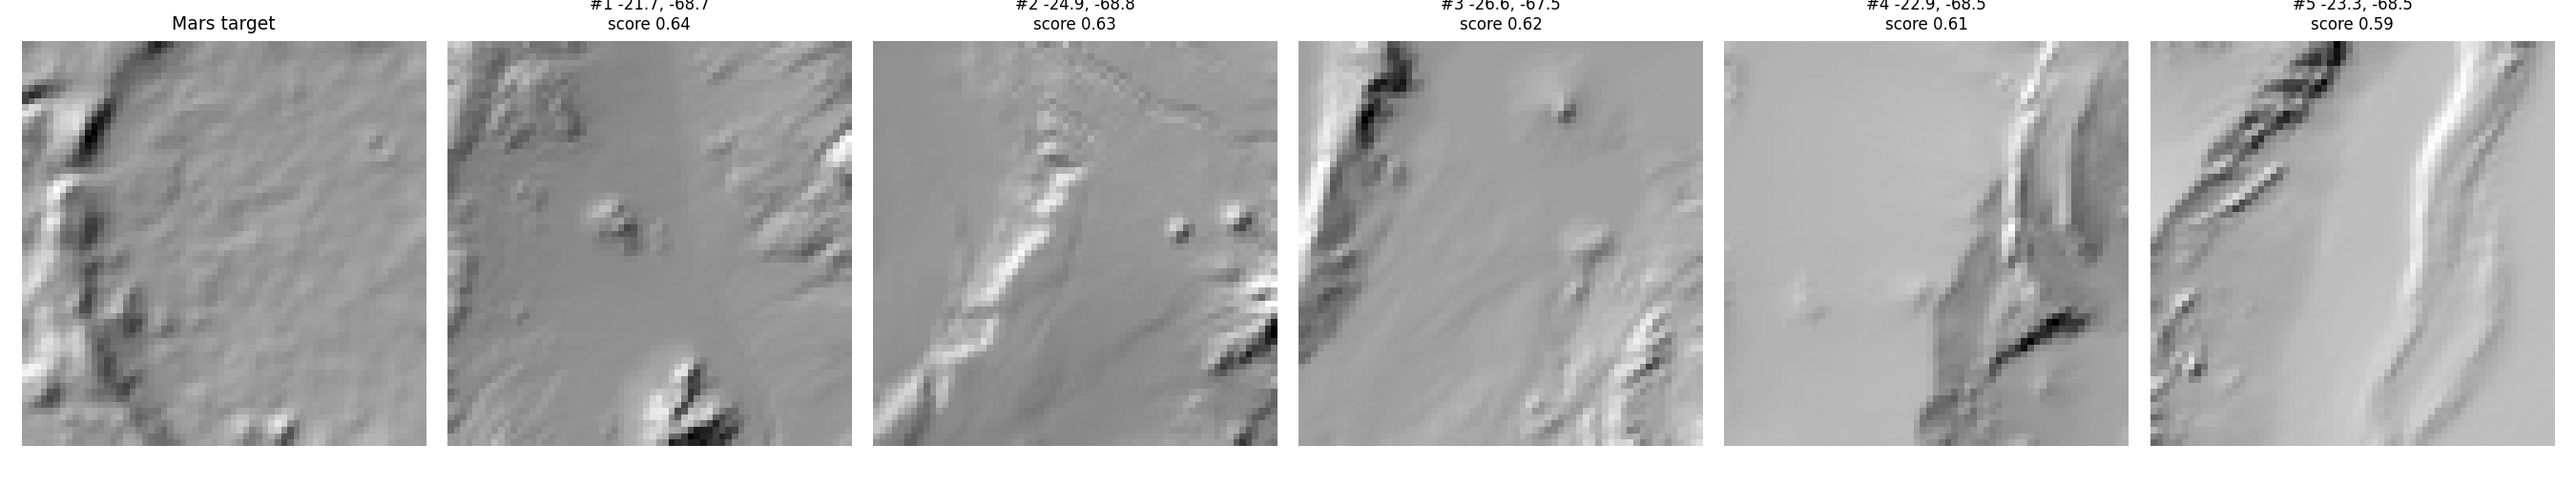

Gate report (what actually ran for this search):
  hard limit: land share     weight       mars            dropped 20 patches
  hard limit: ndvi           weight       mars            dropped 19 patches
  hard limit: precipitation  weight       mars            dropped 0 patches
  thermal_inertia            weight    1  mars none       skipped, no Mars value (no raster and no assumed value)
  diurnal_range              weight    1  mars assumed    used (ASSUMED Mars value)
  mean_temp                  weight    1  mars none       skipped, no Mars value (no raster and no assumed value)
  albedo                     weight    1  mars raster     used
  slope                      weight  0.5  mars mars DEM   used
  roughness                  weight  0.5  mars mars DEM   used
  relief                     weight  0.5  mars mars DEM   used
  pressure                   weight  0.5  mars mars DEM   used
  aridity                    weight    1  mars assumed    used (ASSUMED Mars value)
  vegetati

In [24]:
from IPython.display import Image, display
import config as C
display(Image(str(C.OUT_DIR / "jezero" / "top_matches.png")))
print(open(C.OUT_DIR / "jezero" / "breakdown.txt").read()[:4000])

In [25]:
!mkdir -p /kaggle/working/results && cp -r /kaggle/temp/data/results/* /kaggle/working/results/

## G. Reproducing the results without rebuilding

The raw data is not needed to reproduce the results. The terrain index, gate layers, Earth DEM tiles and a 500 m Mars DEM are published as a public Kaggle dataset, `mars-analog-index`, and this section loads them directly.

To reproduce, attach the dataset as an input, run sections A and B, then the cell below. It restores the index and re-runs the Jezero search shown in section F. No Earthdata account or internet access is required.

In [26]:
DS = "/kaggle/input/datasets/vegash07/mars-analog-index/persist"
import kaggle_helpers as K
K.restore_outputs(DS)
import search
search.run(18.4, 77.5, profile="balanced", top=10, name="jezero")

restored into /kaggle/temp/data
Gate report (what actually ran for this search):
  hard limit: land share     weight       mars            dropped 20 patches
  hard limit: ndvi           weight       mars            dropped 19 patches
  hard limit: precipitation  weight       mars            dropped 0 patches
  thermal_inertia            weight    1  mars none       skipped, no Mars value (no raster and no assumed value)
  diurnal_range              weight    1  mars assumed    used (ASSUMED Mars value)
  mean_temp                  weight    1  mars none       skipped, no Mars value (no raster and no assumed value)
  albedo                     weight    1  mars raster     used
  slope                      weight  0.5  mars mars DEM   used
  roughness                  weight  0.5  mars mars DEM   used
  relief                     weight  0.5  mars mars DEM   used
  pressure                   weight  0.5  mars mars DEM   used
  aridity                    weight    1  mars assumed    used

,lat,lon,tile,mean_elev,relief,dist,dist_ref,index_row,terrain_sim,land_frac,...,aridity_mars,aridity_score,vegetation_earth,vegetation_mars,vegetation_score,latitude_earth,latitude_mars,latitude_score,gate_score,final_score
0,-21.712356,-68.690380,/kaggle/temp/data/earth/dem/s22w069.hgt,3582.840820,811.00,2.750983,6.351715,343,0.566891,1.0,...,0.0,0.858833,0.082357,0.0,0.725477,21.712356,18.4,0.889588,0.703584,0.635238
1,-24.856248,-68.841557,/kaggle/temp/data/earth/dem/s25w069.hgt,3675.305420,1093.25,2.606357,6.351715,745,0.589661,1.0,...,0.0,0.941533,0.079415,0.0,0.735282,24.856248,18.4,0.784792,0.668552,0.629106
2,-26.568465,-67.517499,/kaggle/temp/data/earth/dem/s27w068.hgt,3347.188232,859.25,2.582310,6.351715,1024,0.593447,1.0,...,0.0,0.860667,0.073436,0.0,0.755212,26.568465,18.4,0.727718,0.639968,0.616707
3,-22.856248,-68.531683,/kaggle/temp/data/earth/dem/s23w069.hgt,2994.199707,865.00,2.950256,6.351715,469,0.535518,1.0,...,0.0,0.908083,0.067123,0.0,0.776257,22.856248,18.4,0.851458,0.691554,0.613536
4,-23.280683,-68.530203,/kaggle/temp/data/earth/dem/s24w069.hgt,2530.278564,860.25,3.179235,6.351715,624,0.499468,1.0,...,0.0,0.934750,0.074721,0.0,0.750929,23.280683,18.4,0.837311,0.679356,0.589412
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
456,-20.568465,-66.692762,/kaggle/temp/data/earth/dem/s21w067.hgt,3728.478760,249.00,5.772213,6.351715,168,0.091236,1.0,...,0.0,0.581750,0.124808,0.0,0.583974,20.568465,18.4,0.927718,0.451870,0.271553
457,-26.568465,-66.517499,/kaggle/temp/data/earth/dem/s27w067.hgt,3914.975342,1826.00,5.978846,6.351715,999,0.058704,1.0,...,0.0,0.540083,0.140853,0.0,0.530489,26.568465,18.4,0.727718,0.483137,0.270921
458,-22.424574,-65.377491,/kaggle/temp/data/earth/dem/s23w066.hgt,3945.432617,985.50,6.002561,6.351715,410,0.054970,1.0,...,0.0,0.447083,0.186604,0.0,0.377988,22.424574,18.4,0.865848,0.480365,0.267667
459,-22.424574,-65.533153,/kaggle/temp/data/earth/dem/s23w066.hgt,3667.784180,360.00,6.078590,6.351715,409,0.043000,1.0,...,0.0,0.510083,0.186256,0.0,0.379147,22.424574,18.4,0.865848,0.485822,0.264411
